# Two-teacher distillation for plant-disease classification (BioCLIP-2 + DINOv2 -> MobileNetV3)

**Idea.** Two frozen Vision-Transformer teachers (BioCLIP-2 ViT-L and DINOv2) see the *clean* image once; their predictions and DINOv2 attention maps are cached. A small CNN student (MobileNetV3, about 4-5 M parameters) is trained on the same leaf pasted on a *random new background*, so it cannot rely on the background. Only the student is deployed.

| | Original paper | This project |
|---|---|---|
| Teacher | one frozen ViT | two frozen ViTs, combined per image |
| Student | ConvNeXt / ViT-S (21-50 M) | MobileNetV3 (about 5 M) |
| Input | same image for teacher and student | teacher: clean, student: background-swapped |
| Loss | CE + KD | CE + KD + attention + consistency |

**Evaluation.** (a) PlantVillage held-out images (clean and background-swapped), (b) **PlantDoc field images** on the classes shared with PlantVillage. Group (b) is the real test of robustness.

**Ablation (9 configs x 5 seeds = 45 student runs):** `ce_clean`, `ce_swap`, `orig_style`, `kd_bioclip`, `kd_dino`, `kd_both`, `kd_both_att`, `kd_both_con`, `full`.

#

## 1. GPU check and paths

In [5]:
import torch, os, json, sys
print('torch', torch.__version__, '| cuda:', torch.cuda.is_available())
!nvidia-smi -L
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

from google.colab import drive
drive.mount('/content/drive')

WORK = '/content/work'; CACHE = f'{WORK}/cache'; DATA = '/content/data'
DRIVE_DIR = '/content/drive/MyDrive/plantkd'            # shared folder: cache + results
RESULTS_DIR = f'{DRIVE_DIR}/results'
for d in (WORK, CACHE, DATA, DRIVE_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
%cd /content

torch 2.14.1+cu130 | cuda: True
GPU 0: NVIDIA L4 (UUID: GPU-c05e3a36-860d-3166-5ee7-24df55c749f9)
Mounted at /content/drive
/content


## 2. Install packages

In [6]:
!pip install -q timm open_clip_torch scikit-learn scipy pandas matplotlib
!pip install -q -U transformers

In [7]:
%%writefile /content/plantkd_lib.py
"""plantkd_lib.py
Two frozen ViT teachers (BioCLIP-2, DINOv2) -> MobileNetV3 student, plant-disease classification.
Student sees background-swapped leaves; teachers saw the clean image (outputs cached once).
Loss = CE + KD + attention transfer + consistency (each switchable for ablations).
"""
import os, re, json, time, glob, random
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

IMG = 224
ATT = 16                      # DINOv2 patch-14 at 224 px -> 16 x 16 attention grid
IMNET_MEAN = (0.485, 0.456, 0.406)
IMNET_STD = (0.229, 0.224, 0.225)
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def _norm_t(x, mean, std):
    m = torch.tensor(mean, device=x.device).view(1, 3, 1, 1)
    s = torch.tensor(std, device=x.device).view(1, 3, 1, 1)
    return (x - m) / s


# =====================================================================
# 1. DATA PREPARATION
# =====================================================================
def make_mask(seg_rgb):
    """Leaf alpha mask (uint8 0..255) from a PlantVillage 'segmented' image."""
    from scipy import ndimage as ndi
    corner = seg_rgb[:6, :6].mean()
    if corner > 200:                                   # white background variant
        m = seg_rgb.min(axis=2) < 245
    else:                                              # black background (expected)
        m = seg_rgb.max(axis=2) > 12
    m = ndi.binary_opening(m, iterations=1)
    m = ndi.binary_fill_holes(m)
    m = ndi.binary_erosion(m, iterations=1)            # removes dark halo at the edge
    a = ndi.gaussian_filter(m.astype(np.float32), 0.8)
    return (np.clip(a, 0, 1) * 255).astype(np.uint8)


def _load_pair(c_path, s_path, size):
    from PIL import Image
    clean = np.asarray(Image.open(c_path).convert('RGB').resize((size, size), Image.BILINEAR))
    seg = np.asarray(Image.open(s_path).convert('RGB').resize((size, size), Image.BILINEAR))
    leaf = np.concatenate([seg, make_mask(seg)[..., None]], axis=2)
    return clean, leaf


def pair_plantvillage(pv_root):
    """Match raw/color/<class>/<file> with raw/segmented/<class>/<file>_final_masked.*"""
    col = os.path.join(pv_root, 'raw', 'color')
    seg = os.path.join(pv_root, 'raw', 'segmented')
    classes = sorted(d for d in os.listdir(col) if os.path.isdir(os.path.join(col, d)))
    pairs, miss = [], 0
    for ci, c in enumerate(classes):
        sd = os.path.join(seg, c)
        segmap = {}
        if os.path.isdir(sd):
            for f in os.listdir(sd):
                stem = os.path.splitext(f)[0]
                stem = re.sub(r'_final_masked$', '', stem, flags=re.I)
                segmap[stem.lower()] = os.path.join(sd, f)
        for f in sorted(os.listdir(os.path.join(col, c))):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            sp = segmap.get(os.path.splitext(f)[0].lower())
            if sp is None:
                miss += 1
                continue
            pairs.append((ci, os.path.join(col, c, f), sp))
    return classes, pairs, miss


def prepare_plantvillage(pv_root, out_dir, n_total=20000, test_frac=0.2, seed=0, size=IMG, workers=4):
    os.makedirs(out_dir, exist_ok=True)
    classes, pairs, miss = pair_plantvillage(pv_root)
    print(f'{len(classes)} classes, {len(pairs)} colour/segmented pairs, {miss} colour images without a segmented partner')
    assert len(pairs) > 0.5 * (len(pairs) + miss), 'Too many unmatched files: check the file-name pairing'
    rng = np.random.default_rng(seed)
    by_c = {}
    for p in pairs:
        by_c.setdefault(p[0], []).append(p)
    frac = min(1.0, n_total / len(pairs))
    tr, te = [], []
    for c, lst in by_c.items():
        idx = rng.permutation(len(lst))
        k = min(len(lst), max(10, int(round(len(lst) * frac))))
        sel = [lst[i] for i in idx[:k]]
        nt = max(2, int(round(k * test_frac)))
        te += sel[:nt]; tr += sel[nt:]
    rng.shuffle(tr); rng.shuffle(te)
    for split, items in (('train', tr), ('test', te)):
        n = len(items)
        clean = np.lib.format.open_memmap(f'{out_dir}/{split}_clean.npy', mode='w+', dtype=np.uint8, shape=(n, size, size, 3))
        leaf = np.lib.format.open_memmap(f'{out_dir}/{split}_leaf.npy', mode='w+', dtype=np.uint8, shape=(n, size, size, 4))
        y = np.array([it[0] for it in items], dtype=np.int64)
        t0 = time.time()
        with ThreadPoolExecutor(workers) as ex:
            for i, (c_arr, l_arr) in enumerate(ex.map(lambda it: _load_pair(it[1], it[2], size), items)):
                clean[i] = c_arr; leaf[i] = l_arr
                if (i + 1) % 2000 == 0:
                    print(f'  {split}: {i+1}/{n}  ({time.time()-t0:.0f}s)')
        clean.flush(); leaf.flush()
        np.save(f'{out_dir}/{split}_y.npy', y)
        print(f'{split}: {n} images saved')
    json.dump({'classes': classes}, open(f'{out_dir}/meta.json', 'w'))
    return classes


def prepare_backgrounds(bg_dirs, out_dir, n_train=2000, n_test=500, seed=0, size=IMG):
    from PIL import Image
    paths = []
    for d in bg_dirs:
        for ext in ('jpg', 'jpeg', 'png'):
            paths += glob.glob(os.path.join(d, '**', f'*.{ext}'), recursive=True)
    paths = sorted(set(paths))
    print(f'{len(paths)} background images found')
    assert len(paths) >= n_train + n_test, 'not enough background images'
    random.Random(seed).shuffle(paths)

    def load(p):
        return np.asarray(Image.open(p).convert('RGB').resize((size, size), Image.BILINEAR))
    with ThreadPoolExecutor(4) as ex:
        arr = np.stack(list(ex.map(load, paths[:n_train + n_test])))
    np.save(f'{out_dir}/bg_train.npy', arr[:n_train])
    np.save(f'{out_dir}/bg_test.npy', arr[n_train:])
    print('backgrounds saved:', arr[:n_train].shape, arr[n_train:].shape)


# ---- PlantDoc -> PlantVillage class mapping (rule based, always check the printed table) ----
_PD_SPECIES = {'apple': 'apple', 'pepper': 'pepper', 'blueberry': 'blueberry', 'cherry': 'cherry', 'corn': 'corn',
               'peach': 'peach', 'potato': 'potato', 'raspberry': 'raspberry', 'soyabean': 'soybean',
               'soybean': 'soybean', 'squash': 'squash', 'strawberry': 'strawberry', 'tomato': 'tomato', 'grape': 'grape'}
_PD_COND = [('gray', 'gray'), ('corn leaf blight', 'northern'), ('northern', 'northern'), ('scab', 'scab'),
            ('rust', 'rust'), ('black rot', 'black rot'), ('early blight', 'early blight'),
            ('late blight', 'late blight'), ('septoria', 'septoria'), ('bacterial', 'bacterial'),
            ('mosaic', 'mosaic'), ('yellow', 'yellow'), ('mold', 'leaf mold'), ('spider', 'spider'),
            ('powdery', 'powdery')]


def _norm(s):
    return re.sub(r'\s+', ' ', re.sub(r'[_,()]', ' ', s.lower())).strip()


def map_plantdoc_class(pd_name, pv_classes, override=None):
    """Return PlantVillage class index for a PlantDoc class name, or None."""
    n = _norm(pd_name)
    if override and pd_name in override:
        return pv_classes.index(override[pd_name]) if override[pd_name] else None
    sp = next((v for k, v in _PD_SPECIES.items() if k in n), None)
    if sp is None:
        return None
    cond = next((v for k, v in _PD_COND if k in n), None)
    if cond is None and sp == 'pepper' and 'leaf spot' in n:
        cond = 'bacterial'
    if cond is None:
        cond = 'healthy' if 'leaf' in n else None
    if cond is None:
        return None
    for i, c in enumerate(pv_classes):
        cn = _norm(c)
        if sp in cn and cond in cn:
            return i
    return None


def prepare_plantdoc(pd_root, out_dir, pv_classes, override=None, size=IMG):
    from PIL import Image
    paths = []
    for ext in ('jpg', 'jpeg', 'png', 'JPG', 'JPEG', 'PNG'):
        paths += glob.glob(os.path.join(pd_root, '**', f'*.{ext}'), recursive=True)
    paths = sorted(set(paths))
    names = sorted({os.path.basename(os.path.dirname(p)) for p in paths})
    cmap = {n: map_plantdoc_class(n, pv_classes, override) for n in names}
    print('PlantDoc class -> PlantVillage class')
    for n, i in cmap.items():
        print(f'  {n:45s} -> {pv_classes[i] if i is not None else "-- unmapped --"}')
    keep = [(p, cmap[os.path.basename(os.path.dirname(p))]) for p in paths]
    keep = [(p, i) for p, i in keep if i is not None]
    print(f'{len(keep)} of {len(paths)} PlantDoc images are in classes shared with PlantVillage')

    def load(p):
        return np.asarray(Image.open(p).convert('RGB').resize((size, size), Image.BILINEAR))
    with ThreadPoolExecutor(4) as ex:
        arr = np.stack(list(ex.map(load, [p for p, _ in keep])))
    np.save(f'{out_dir}/pd_clean.npy', arr)
    np.save(f'{out_dir}/pd_y.npy', np.array([i for _, i in keep], dtype=np.int64))
    return cmap


# =====================================================================
# 2. TEACHERS: feature extraction, linear heads, cached outputs
# =====================================================================
@torch.no_grad()
def extract_bioclip(arrays, device, bs=128, name='hf-hub:imageomics/bioclip-2'):
    """Returns list of (N,D) L2-normalised image embeddings, one per input uint8 array (N,H,W,3)."""
    import open_clip
    model, _, _ = open_clip.create_model_and_transforms(name)
    model = model.to(device).eval().half()
    outs = []
    for arr in arrays:
        feats = []
        for i in range(0, len(arr), bs):
            x = torch.from_numpy(np.ascontiguousarray(arr[i:i + bs])).to(device).permute(0, 3, 1, 2).float() / 255
            x = _norm_t(x, CLIP_MEAN, CLIP_STD).half()
            f = model.encode_image(x).float()
            feats.append(F.normalize(f, dim=-1).cpu())
        outs.append(torch.cat(feats))
    del model; torch.cuda.empty_cache()
    return outs


@torch.no_grad()
def extract_dino(arrays, device, bs=64, name='facebook/dinov2-base', want_attn_for=0):
    """Features = [CLS, mean patch]. Also returns the last-layer CLS->patch attention (head-mean) for arrays[want_attn_for]."""
    from transformers import AutoModel
    model = AutoModel.from_pretrained(name, attn_implementation='eager').to(device).eval().half()
    outs, attn_out = [], None
    for k, arr in enumerate(arrays):
        feats, atts = [], []
        for i in range(0, len(arr), bs):
            x = torch.from_numpy(np.ascontiguousarray(arr[i:i + bs])).to(device).permute(0, 3, 1, 2).float() / 255
            x = _norm_t(x, IMNET_MEAN, IMNET_STD).half()
            need = (k == want_attn_for)
            o = model(pixel_values=x, output_attentions=need)
            h = o.last_hidden_state.float()
            feats.append(torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).cpu())
            if need:
                a = o.attentions[-1][:, :, 0, 1:].float().mean(1)          # B, N_patches
                atts.append(a.reshape(-1, ATT, ATT).cpu())
        outs.append(torch.cat(feats))
        if k == want_attn_for:
            attn_out = torch.cat(atts)
    del model; torch.cuda.empty_cache()
    return outs, attn_out


def fit_linear_head(X, y, C, steps=300, lr=5e-3, wd=1e-4):
    head = nn.Linear(X.shape[1], C).to(X.device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    for _ in range(steps):
        opt.zero_grad(set_to_none=True)
        F.cross_entropy(head(X), y).backward()
        opt.step()
    return head


def head_outputs(F_tr, y_tr, F_others, C, device, k=5, seed=0):
    """Out-of-fold logits for train features (so KD targets are not over-confident) + logits of a
    head fitted on all train data for every array in F_others (dict name -> features)."""
    from sklearn.model_selection import StratifiedKFold
    F_tr = F_tr.to(device).float()
    y = torch.as_tensor(y_tr, device=device)
    mu, sd = F_tr.mean(0, keepdim=True), F_tr.std(0, keepdim=True) + 1e-6
    Z = (F_tr - mu) / sd
    oof = torch.zeros(len(Z), C)
    for tr_i, va_i in StratifiedKFold(k, shuffle=True, random_state=seed).split(np.zeros(len(Z)), y.cpu().numpy()):
        tr_i, va_i = torch.as_tensor(tr_i, device=device), torch.as_tensor(va_i, device=device)
        h = fit_linear_head(Z[tr_i], y[tr_i], C)
        with torch.no_grad():
            oof[va_i.cpu()] = h(Z[va_i]).cpu()
    h = fit_linear_head(Z, y, C)
    with torch.no_grad():
        outs = {n: h((f.to(device).float() - mu) / sd).cpu() for n, f in F_others.items()}
    return oof, outs


# =====================================================================
# 3. STUDENT: augmentation, losses
# =====================================================================
def composite(leaf, bg_bank, gen=None):
    """leaf: (B,4,H,W) float 0..1 ; bg_bank: (M,3,H,W) uint8 on the same device. Returns (B,3,H,W) float."""
    B = leaf.shape[0]
    rgb, a = leaf[:, :3], leaf[:, 3:4]
    idx = torch.randint(0, bg_bank.shape[0], (B,), device=leaf.device, generator=gen)
    bg = bg_bank[idx].float() / 255.0
    flip = torch.rand(B, device=leaf.device, generator=gen) < 0.5
    bg = torch.where(flip[:, None, None, None], bg.flip(3), bg)
    return rgb * a + bg * (1 - a)


def rand_flip(x, att=None):
    """Same random h/v flips for the image and the teacher attention map (keeps them aligned)."""
    B = x.shape[0]
    hf = torch.rand(B, device=x.device) < 0.5
    vf = torch.rand(B, device=x.device) < 0.5
    x = torch.where(hf[:, None, None, None], x.flip(3), x)
    x = torch.where(vf[:, None, None, None], x.flip(2), x)
    if att is not None:
        att = torch.where(hf[:, None, None], att.flip(2), att)
        att = torch.where(vf[:, None, None], att.flip(1), att)
    return x, att


def photometric(x):
    B = x.shape[0]
    b = 0.8 + 0.4 * torch.rand(B, 1, 1, 1, device=x.device)
    c = 0.8 + 0.4 * torch.rand(B, 1, 1, 1, device=x.device)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - m) * c + m * b).clamp(0, 1)


def combine_teachers(zs, T, mode='conf'):
    """Per-image combination of teacher logits into one tempered target distribution."""
    qs = [F.softmax(z / T, -1) for z in zs]
    if len(qs) == 1:
        return qs[0]
    if mode == 'mean':
        return sum(qs) / len(qs)
    conf = torch.stack([F.softmax(z, -1).max(-1).values for z in zs], 1)
    w = conf / conf.sum(1, keepdim=True)
    return sum(w[:, k:k + 1] * qs[k] for k in range(len(qs)))


def kd_loss(student_logits, q_teacher, T):
    return (T * T) * F.kl_div(F.log_softmax(student_logits / T, -1), q_teacher, reduction='batchmean')


def student_attention(feat):
    a = feat.float().pow(2).mean(1, keepdim=True)
    a = F.interpolate(a, size=(ATT, ATT), mode='bilinear', align_corners=False).flatten(1)
    return a / (a.sum(1, keepdim=True) + 1e-8)


def att_loss(a_s, a_t):
    return (a_t * (torch.log(a_t + 1e-8) - torch.log(a_s + 1e-8))).sum(1).mean()


def consistency_loss(la, lb):
    return 0.5 * (F.kl_div(F.log_softmax(lb, -1), F.softmax(la, -1), reduction='batchmean') +
                  F.kl_div(F.log_softmax(la, -1), F.softmax(lb, -1), reduction='batchmean'))


# =====================================================================
# 4. EXPERIMENT CONFIGS
# =====================================================================
CONFIGS = {
    # name:         view of student input, KD teacher(s), attention loss, consistency loss
    'ce_clean':    dict(view='clean', kd=None,      att=False, con=False),   # plain student, original images
    'ce_swap':     dict(view='swap',  kd=None,      att=False, con=False),   # + background swap only
    'orig_style':  dict(view='clean', kd='dino',    att=False, con=False),   # one teacher, same image, CE+KD (original-paper style)
    'kd_bioclip':  dict(view='swap',  kd='bioclip', att=False, con=False),
    'kd_dino':     dict(view='swap',  kd='dino',    att=False, con=False),
    'kd_both':     dict(view='swap',  kd='both',    att=False, con=False),
    'kd_both_att': dict(view='swap',  kd='both',    att=True,  con=False),
    'kd_both_con': dict(view='swap',  kd='both',    att=False, con=True),
    'full':        dict(view='swap',  kd='both',    att=True,  con=True),
}

DEFAULT_HP = dict(arch='mobilenetv3_large_100', pretrained=True, epochs=12, bs=128, lr=1e-3, wd=1e-2,
                  T=4.0, lam_kd=1.0, lam_att=1.0, lam_con=1.0, teacher_mix='conf', amp=True)


# =====================================================================
# 5. WORKSPACE (loads cached arrays) + EVALUATION
# =====================================================================
class Workspace:
    def __init__(self, cache_dir, device):
        self.device = device
        meta = json.load(open(f'{cache_dir}/meta.json'))
        self.classes = meta['classes']; self.C = len(self.classes)
        L = lambda n: np.load(f'{cache_dir}/{n}.npy', mmap_mode='r')
        self.tr_clean, self.tr_leaf, self.tr_y = L('train_clean'), L('train_leaf'), np.load(f'{cache_dir}/train_y.npy')
        self.te_clean, self.te_leaf, self.te_y = L('test_clean'), L('test_leaf'), np.load(f'{cache_dir}/test_y.npy')
        self.pd_clean = L('pd_clean'); self.pd_y = np.load(f'{cache_dir}/pd_y.npy')
        tc = np.load(f'{cache_dir}/teacher_cache.npz')
        self.t = {k: torch.from_numpy(tc[k]) for k in tc.files}
        to_bank = lambda n: torch.from_numpy(np.load(f'{cache_dir}/{n}.npy')).permute(0, 3, 1, 2).contiguous().to(device)
        self.bg_train, self.bg_test = to_bank('bg_train'), to_bank('bg_test')
        self.tr_y_t = torch.from_numpy(self.tr_y).to(device)
        print(f'train {len(self.tr_y)} | test {len(self.te_y)} | PlantDoc(shared classes) {len(self.pd_y)} | '
              f'C={self.C} | bg train/test {len(self.bg_train)}/{len(self.bg_test)}')


def _metrics(logits, y, allowed=None):
    from sklearn.metrics import f1_score
    lg = logits.clone()
    if allowed is not None:
        mask = torch.full_like(lg, float('-inf')); mask[:, allowed] = 0
        lg = lg + mask
    pred = lg.argmax(1).numpy()
    return dict(acc=float((pred == y).mean()), f1=float(f1_score(y, pred, average='macro', labels=sorted(set(y.tolist())), zero_division=0)))


@torch.no_grad()
def _predict(model, get_batch, n, device, bs=256, use_amp=False):
    model.eval(); outs = []
    for i in range(0, n, bs):
        x = _norm_t(get_batch(i, min(n, i + bs)), IMNET_MEAN, IMNET_STD)
        with torch.autocast(device_type='cuda' if device == 'cuda' else 'cpu', dtype=torch.float16, enabled=use_amp):
            outs.append(model(x).float().cpu())
    return torch.cat(outs)


def evaluate_student(model, ws, device, use_amp=False):
    dev = device
    clean_batch = lambda arr: (lambda a, b: torch.from_numpy(np.ascontiguousarray(arr[a:b])).to(dev).permute(0, 3, 1, 2).float() / 255)
    res = {}
    lg = _predict(model, clean_batch(ws.te_clean), len(ws.te_y), dev, use_amp=use_amp)
    m = _metrics(lg, ws.te_y); res['pv_clean_acc'], res['pv_clean_f1'] = m['acc'], m['f1']
    gen = torch.Generator(device=dev); gen.manual_seed(1234)

    def swap_batch(a, b):
        leaf = torch.from_numpy(np.ascontiguousarray(ws.te_leaf[a:b])).to(dev).permute(0, 3, 1, 2).float() / 255
        return composite(leaf, ws.bg_test, gen)
    lg = _predict(model, swap_batch, len(ws.te_y), dev, use_amp=use_amp)
    m = _metrics(lg, ws.te_y); res['pv_swap_acc'], res['pv_swap_f1'] = m['acc'], m['f1']
    allowed = sorted(set(ws.pd_y.tolist()))
    lg = _predict(model, clean_batch(ws.pd_clean), len(ws.pd_y), dev, use_amp=use_amp)
    m = _metrics(lg, ws.pd_y, allowed); res['pd_acc'], res['pd_f1'] = m['acc'], m['f1']
    return res


def teacher_report(ws):
    """Accuracy of the frozen teachers (linear heads) on PV-test and PlantDoc, individually and combined."""
    out = {}
    allowed = sorted(set(ws.pd_y.tolist()))
    for tag, ys, keys, al in (('pv_test', ws.te_y, 'test', None), ('plantdoc', ws.pd_y, 'pd', allowed)):
        zb, zd = ws.t[f'bio_{keys}'], ws.t[f'dino_{keys}']
        comb = torch.log(combine_teachers([zb, zd], 1.0) + 1e-9)
        for n, z in (('bioclip', zb), ('dino', zd), ('both', comb)):
            m = _metrics(z, ys, al); out[f'{n}_{tag}_acc'] = m['acc']; out[f'{n}_{tag}_f1'] = m['f1']
    return out


# =====================================================================
# 6. TRAINING
# =====================================================================
def train_one(ws, cfg_name, seed, hp=None, device='cuda', verbose=True, save_path=None):
    import timm
    hp = {**DEFAULT_HP, **(hp or {})}
    cfg = CONFIGS[cfg_name]
    assert not (cfg['con'] and cfg['view'] == 'clean'), 'consistency needs background-swapped views'
    set_seed(seed)
    use_amp = bool(hp['amp'] and device == 'cuda')
    model = timm.create_model(hp['arch'], pretrained=hp['pretrained'], num_classes=ws.C).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    feats = {}
    hook = model.blocks.register_forward_hook(lambda m, i, o: feats.__setitem__('f', o))
    N, bs, E = len(ws.tr_y), hp['bs'], hp['epochs']
    spe = N // bs
    opt = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp['lr'], total_steps=E * spe, pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    zs_all = {'bioclip': ws.t['bio_oof'].to(device), 'dino': ws.t['dino_oof'].to(device)}
    kd_names = {None: [], 'bioclip': ['bioclip'], 'dino': ['dino'], 'both': ['bioclip', 'dino']}[cfg['kd']]
    attn_all = ws.t['attn_tr'].to(device).float()
    rng = np.random.default_rng(seed)
    t0 = time.time(); hist = []

    for ep in range(E):
        model.train(); perm = rng.permutation(N); run = {'loss': 0., 'ce': 0., 'kd': 0., 'att': 0., 'con': 0.}
        for it in range(spe):
            bi = np.sort(perm[it * bs:(it + 1) * bs]); bit = torch.from_numpy(bi).to(device)
            y = ws.tr_y_t[bit]; a_t = attn_all[bit]
            if cfg['view'] == 'clean':
                x0 = torch.from_numpy(ws.tr_clean[bi]).to(device).permute(0, 3, 1, 2).float() / 255
                x0, a_t = rand_flip(x0, a_t)
                views = [x0]
            else:
                leaf = torch.from_numpy(ws.tr_leaf[bi]).to(device).permute(0, 3, 1, 2).float() / 255
                leaf, a_t = rand_flip(leaf, a_t)
                views = [composite(leaf, ws.bg_train)]
                if cfg['con']:
                    views.append(composite(leaf, ws.bg_train))
            x = torch.cat([_norm_t(photometric(v), IMNET_MEAN, IMNET_STD) for v in views])
            R = len(views)
            with torch.autocast(device_type='cuda' if device == 'cuda' else 'cpu', dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            logits = logits.float()
            ce = F.cross_entropy(logits, y.repeat(R))
            loss = ce; kd = att = con = torch.zeros((), device=device)
            if kd_names:
                q = combine_teachers([zs_all[k][bit] for k in kd_names], hp['T'], hp['teacher_mix'])
                kd = kd_loss(logits, q.repeat(R, 1), hp['T']); loss = loss + hp['lam_kd'] * kd
            if cfg['att']:
                at = a_t.flatten(1); at = at / (at.sum(1, keepdim=True) + 1e-8)
                att = att_loss(student_attention(feats['f']), at.repeat(R, 1)); loss = loss + hp['lam_att'] * att
            if cfg['con']:
                la, lb = logits.chunk(2); con = consistency_loss(la, lb); loss = loss + hp['lam_con'] * con
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            for k, v in zip(run, (loss, ce, kd, att, con)):
                run[k] += float(v) / spe
        hist.append({k: round(v, 4) for k, v in run.items()})
        if verbose:
            print(f'  ep {ep+1:2d}/{E} ' + ' '.join(f'{k}={v:.3f}' for k, v in run.items()) + f'  [{time.time()-t0:.0f}s]')
    res = evaluate_student(model, ws, device, use_amp)
    hook.remove()
    if save_path:
        torch.save(model.state_dict(), save_path)
    res.update(config=cfg_name, seed=seed, params=n_params, train_seconds=round(time.time() - t0, 1), hp=hp, history=hist)
    return res


def run_and_save(ws, cfg_name, seed, results_dir, hp=None, device='cuda', save_weights=False):
    os.makedirs(results_dir, exist_ok=True)
    path = f'{results_dir}/{cfg_name}_seed{seed}.json'
    if os.path.exists(path):
        print(f'skip {cfg_name} seed {seed} (already done)')
        return json.load(open(path))
    print(f'=== {cfg_name} | seed {seed} ===')
    wp = f'{results_dir}/{cfg_name}_seed{seed}.pth' if save_weights else None
    res = train_one(ws, cfg_name, seed, hp, device, save_path=wp)
    json.dump(res, open(path, 'w'), indent=1)
    print({k: round(v, 4) for k, v in res.items() if k.endswith(('acc', 'f1'))})
    return res


def aggregate(results_dir):
    import pandas as pd
    rows = [json.load(open(p)) for p in sorted(glob.glob(f'{results_dir}/*.json')) if 'teacher' not in os.path.basename(p)]
    df = pd.DataFrame([{k: r[k] for k in r if k not in ('hp', 'history')} for r in rows])
    metrics = ['pv_clean_acc', 'pv_swap_acc', 'pd_acc', 'pv_clean_f1', 'pv_swap_f1', 'pd_f1']
    g = df.groupby('config')[metrics]
    mean, std = g.mean() * 100, g.std() * 100
    table = mean.round(2).astype(str) + ' ± ' + std.fillna(0).round(2).astype(str)
    table['n_seeds'] = df.groupby('config').size()
    order = [c for c in CONFIGS if c in table.index]
    return df, table.loc[order]


Writing /content/plantkd_lib.py


## 4. Download the datasets


In [8]:
%cd /content/data
!git clone --depth 1 --filter=blob:none --sparse https://github.com/spMohanty/PlantVillage-Dataset.git
%cd /content/data/PlantVillage-Dataset
!git sparse-checkout set raw/color raw/segmented leaf_grouping
!ls
!ls raw/color | head -50
!ls raw/color | wc -l
!ls raw/segmented | wc -l
!ls leaf_grouping | head
%cd /content

/content/data
Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 206, done.
remote: Counting objects: 100% (206/206), done.
remote: Compressing objects: 100% (169/169), done.
remote: Total 206 (delta 37), reused 204 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (206/206), 7.47 MiB | 27.24 MiB/s, done.
Resolving deltas: 100% (37/37), done.
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 9 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 255.05 KiB | 14.17 MiB/s, done.
/content/data/PlantVillage-Dataset
remote: Enumerating objects: 108619, done.
remote: Counting objects: 100% (108619/108619), done.
remote: Compressing objects: 100% (108601/108601), done.
remote: Total 108619 (delta 18), reused 108619 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (108619/108619), 1.23 GiB | 14.93 MiB/s, done.
Resolving deltas: 100% (1

In [9]:
# PlantDoc (cropped classification version) - field images, used for testing only
%cd /content/data
!git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git
!ls PlantDoc-Dataset
!find PlantDoc-Dataset -maxdepth 2 -type d | head -20
%cd /content

/content/data
Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 18.66 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.
LICENSE.txt  PlantDoc_Examples.png  README.md  test  train
PlantDoc-Dataset
PlantDoc-Dataset/.git
PlantDoc-Dataset/.git/objects
PlantDoc-Dataset/.git/hooks
PlantDoc-Dataset/.git/branches
PlantDoc-Dataset/.git/refs
PlantDoc-Dataset/.git/logs
PlantDoc-Dataset/.git/info
PlantDoc-Dataset/test
PlantDoc-Dataset/test/Corn leaf blight
PlantDoc-Dataset/test/Blueberry leaf
PlantDoc-Dataset/test/Potato leaf late blight
PlantDoc-Dataset/test/Apple Scab Leaf
PlantDoc-Dataset/test/grape leaf black rot
PlantDoc-Dataset/test/Tomato mold leaf
PlantDoc-Dataset/test/Strawberry leaf
PlantDoc-Dataset

In [10]:
# Background textures: Describable Textures Dataset (about 5,640 images)
import torchvision
_ = torchvision.datasets.DTD(root='/content/data/dtd', split='train', download=True)
!find /content/data/dtd -name "*.jpg" | wc -l

100%|██████████| 625M/625M [00:34<00:00, 17.9MB/s]


5640


In [11]:
# OPTIONAL: extra natural-scene backgrounds from Places365 (validation set, about 500 MB).
# Uncomment only if you want them, then add '/content/data/places' to BG_DIRS in section 5.
# !mkdir -p /content/data/places && cd /content/data/places && wget -q http://data.csail.mit.edu/places/places365/val_256.tar && tar -xf val_256.tar

## 5. Preprocess: PlantVillage arrays, backgrounds, PlantDoc
Everything is resized to 224 x 224 and stored as uint8 arrays, so training is not limited by image decoding.

In [12]:
import plantkd_lib as K
classes = K.prepare_plantvillage('/content/data/PlantVillage-Dataset', CACHE, n_total=20000, test_frac=0.2, seed=0)

38 classes, 53109 colour/segmented pairs, 1196 colour images without a segmented partner
  train: 2000/16005  (7s)
  train: 4000/16005  (13s)
  train: 6000/16005  (20s)
  train: 8000/16005  (26s)
  train: 10000/16005  (33s)
  train: 12000/16005  (39s)
  train: 14000/16005  (46s)
  train: 16000/16005  (52s)
train: 16005 images saved
  test: 2000/3997  (7s)
test: 3997 images saved


In [13]:
BG_DIRS = ['/content/data/dtd']
K.prepare_backgrounds(BG_DIRS, CACHE, n_train=2000, n_test=500)

5640 background images found
backgrounds saved: (2000, 224, 224, 3) (500, 224, 224, 3)


**EDIT after reading the printed table.** The PlantDoc -> PlantVillage class mapping is rule-based. Check every line. Fix a wrong or unmapped class in `PLANTDOC_OVERRIDE`, using the exact PlantDoc folder name as the key and the exact PlantVillage class as the value (`None` drops the class). Then re-run the cell.

In [14]:
PLANTDOC_OVERRIDE = {
    # 'Some PlantDoc folder name': 'Exact___PlantVillage_class',
}
cmap = K.prepare_plantdoc('/content/data/PlantDoc-Dataset', CACHE, classes, override=PLANTDOC_OVERRIDE)

PlantDoc class -> PlantVillage class
  Apple Scab Leaf                               -> Apple___Apple_scab
  Apple leaf                                    -> Apple___healthy
  Apple rust leaf                               -> Apple___Cedar_apple_rust
  Bell_pepper leaf                              -> Pepper,_bell___healthy
  Bell_pepper leaf spot                         -> Pepper,_bell___Bacterial_spot
  Blueberry leaf                                -> Blueberry___healthy
  Cherry leaf                                   -> Cherry_(including_sour)___healthy
  Corn Gray leaf spot                           -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Corn leaf blight                              -> Corn_(maize)___Northern_Leaf_Blight
  Corn rust leaf                                -> Corn_(maize)___Common_rust_
  Peach leaf                                    -> Peach___healthy
  PlantDoc-Dataset                              -> -- unmapped --
  Potato leaf early blight            

### Sanity check: clean image, leaf on new background, leaf mask
Look at this carefully. If the masks cut off leaf parts or keep black borders.

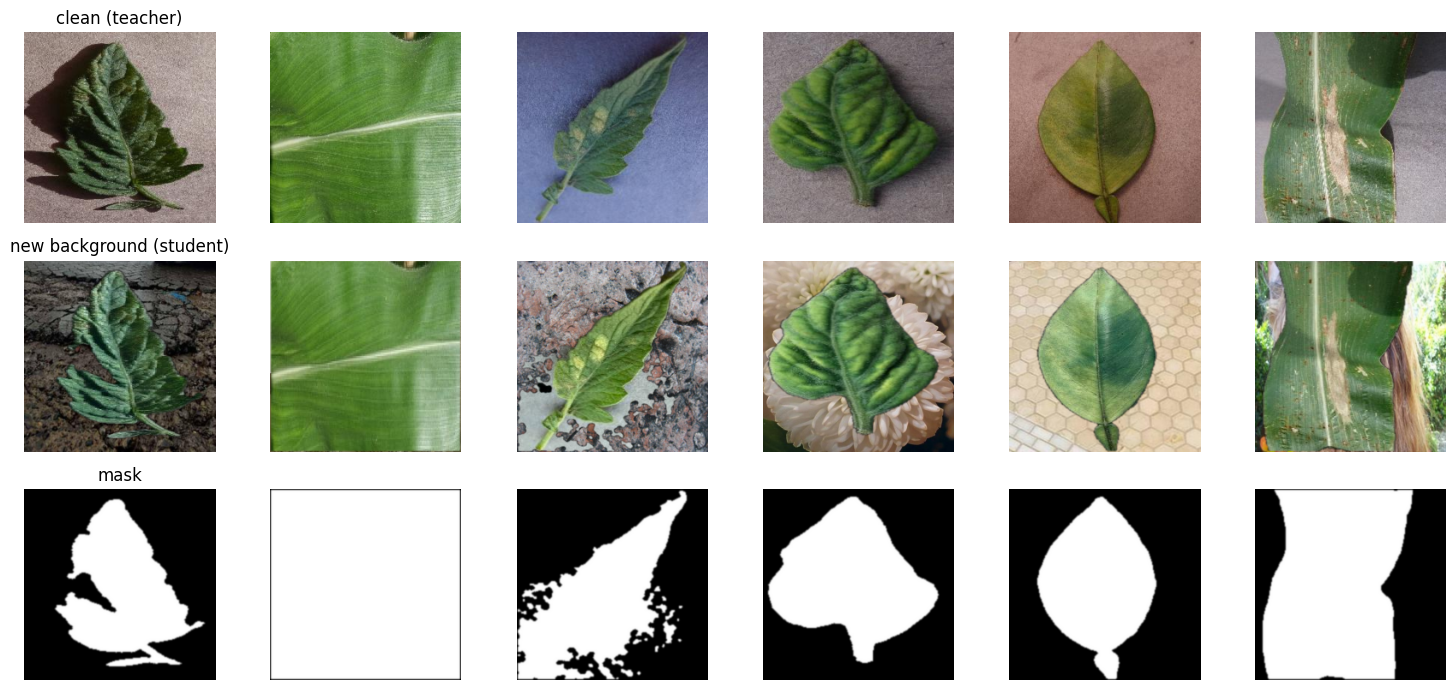

In [15]:
import numpy as np, matplotlib.pyplot as plt
tc = np.load(f'{CACHE}/train_clean.npy', mmap_mode='r'); tl = np.load(f'{CACHE}/train_leaf.npy', mmap_mode='r')
bg = np.load(f'{CACHE}/bg_train.npy')
fig, ax = plt.subplots(3, 6, figsize=(15, 7))
for j in range(6):
    leaf = np.asarray(tl[j]); a = leaf[..., 3:4] / 255.
    comp = (leaf[..., :3] * a + bg[j] * (1 - a)).astype(np.uint8)
    ax[0, j].imshow(tc[j]); ax[1, j].imshow(comp); ax[2, j].imshow(leaf[..., 3], cmap='gray')
    for r in range(3): ax[r, j].axis('off')
ax[0, 0].set_title('clean (teacher)'); ax[1, 0].set_title('new background (student)'); ax[2, 0].set_title('mask')
plt.tight_layout(); plt.show()

## 6. Teachers: features, linear heads, cached outputs
Runs BioCLIP-2 and DINOv2 once over the train, test and PlantDoc images .

In [16]:
import numpy as np, torch, json
DINO_NAME = 'facebook/dinov2-base'
L = lambda n: np.load(f'{CACHE}/{n}.npy', mmap_mode='r')
tr, te, pdc = L('train_clean'), L('test_clean'), L('pd_clean')
y_tr = np.load(f'{CACHE}/train_y.npy'); C = len(classes)

print('BioCLIP-2 features ...')
Fb_tr, Fb_te, Fb_pd = K.extract_bioclip([tr, te, pdc], DEVICE)
print('DINOv2 features + attention maps ...')
(Fd_tr, Fd_te, Fd_pd), attn_tr = K.extract_dino([tr, te, pdc], DEVICE, name=DINO_NAME, want_attn_for=0)

print('Linear heads (5-fold out-of-fold for train) ...')
bio_oof, bo = K.head_outputs(Fb_tr, y_tr, {'test': Fb_te, 'pd': Fb_pd}, C, DEVICE)
dino_oof, do = K.head_outputs(Fd_tr, y_tr, {'test': Fd_te, 'pd': Fd_pd}, C, DEVICE)

np.savez(f'{CACHE}/teacher_cache.npz',
         bio_oof=bio_oof.numpy(), dino_oof=dino_oof.numpy(),
         bio_test=bo['test'].numpy(), bio_pd=bo['pd'].numpy(),
         dino_test=do['test'].numpy(), dino_pd=do['pd'].numpy(),
         attn_tr=attn_tr.numpy().astype(np.float32))
print('saved teacher_cache.npz; attention maps:', tuple(attn_tr.shape))

BioCLIP-2 features ...


open_clip_config.json:   0%|          | 0.00/534 [00:00<?, ?B/s]

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/content/plantkd_lib.py:210: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(np.ascontiguousarray(arr[i:i + bs])).to(device).permute(0, 3, 1, 2).float() / 255


DINOv2 features + attention maps ...


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Linear heads (5-fold out-of-fold for train) ...
saved teacher_cache.npz; attention maps: (16005, 16, 16)


## 7. Load everything and report the teachers' own accuracy
These numbers go in the paper as the teacher upper reference.

In [17]:
import importlib; importlib.reload(K)
ws = K.Workspace(CACHE, DEVICE)
tr_rep = K.teacher_report(ws)
for k, v in tr_rep.items(): print(f'{k:28s} {v*100:6.2f}')
json.dump(tr_rep, open(f'{RESULTS_DIR}/teacher_report.json', 'w'), indent=1)

train 16005 | test 3997 | PlantDoc(shared classes) 2578 | C=38 | bg train/test 2000/500
bioclip_pv_test_acc           97.70
bioclip_pv_test_f1            97.29
dino_pv_test_acc              98.87
dino_pv_test_f1               98.53
both_pv_test_acc              99.05
both_pv_test_f1               98.76
bioclip_plantdoc_acc          56.32
bioclip_plantdoc_f1           50.40
dino_plantdoc_acc             46.08
dino_plantdoc_f1              39.73
both_plantdoc_acc             53.65
both_plantdoc_f1              47.83


## 8. Share the cache with teammates through Google Drive (optional)
**Person A** runs the first cell after section 7 (about 7 GB; make sure your Drive has room). **Teammates** skip sections 4-7: run sections 1-3, then the restore cell, then section 7's loading cell.

In [18]:

!mkdir -p {DRIVE_DIR}/cache && cp -r {CACHE}/* {DRIVE_DIR}/cache/ && du -sh {DRIVE_DIR}/cache

7.3G	/content/drive/MyDrive/plantkd/cache


In [19]:

!mkdir -p {CACHE} && cp -r {DRIVE_DIR}/cache/* {CACHE}/ && ls {CACHE}

bg_test.npy   pd_clean.npy	 test_clean.npy  train_clean.npy
bg_train.npy  pd_y.npy		 test_leaf.npy	 train_leaf.npy
meta.json     teacher_cache.npz  test_y.npy	 train_y.npy


In [22]:
MY_CONFIGS = ['ce_clean', 'ce_swap', 'orig_style','kd_bioclip', 'kd_dino' , 'kd_both', 'kd_both_att', 'kd_both_con', 'full']
MY_SEEDS = [0, 1, 2, 3, 4]
HP = dict(epochs=12)
for cfg in MY_CONFIGS:
    for seed in MY_SEEDS:
        K.run_and_save(ws, cfg, seed, RESULTS_DIR, hp=HP, device=DEVICE)

skip ce_clean seed 0 (already done)
skip ce_clean seed 1 (already done)
skip ce_clean seed 2 (already done)
skip ce_clean seed 3 (already done)
skip ce_clean seed 4 (already done)
skip ce_swap seed 0 (already done)
skip ce_swap seed 1 (already done)
skip ce_swap seed 2 (already done)
skip ce_swap seed 3 (already done)
skip ce_swap seed 4 (already done)
skip orig_style seed 0 (already done)
skip orig_style seed 1 (already done)
skip orig_style seed 2 (already done)
skip orig_style seed 3 (already done)
skip orig_style seed 4 (already done)
=== kd_bioclip | seed 0 ===


/content/plantkd_lib.py:450: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/plantkd_lib.py:489: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  ep  1/12 loss=20.535 ce=1.825 kd=18.710 att=0.000 con=0.000  [16s]
  ep  2/12 loss=3.162 ce=0.160 kd=3.001 att=0.000 con=0.000  [32s]
  ep  3/12 loss=2.248 ce=0.082 kd=2.166 att=0.000 con=0.000  [47s]
  ep  4/12 loss=1.857 ce=0.052 kd=1.805 att=0.000 con=0.000  [63s]
  ep  5/12 loss=1.670 ce=0.040 kd=1.630 att=0.000 con=0.000  [79s]
  ep  6/12 loss=1.495 ce=0.034 kd=1.462 att=0.000 con=0.000  [95s]
  ep  7/12 loss=1.347 ce=0.026 kd=1.321 att=0.000 con=0.000  [111s]
  ep  8/12 loss=1.236 ce=0.022 kd=1.214 att=0.000 con=0.000  [126s]
  ep  9/12 loss=1.140 ce=0.019 kd=1.121 att=0.000 con=0.000  [142s]
  ep 10/12 loss=1.089 ce=0.020 kd=1.069 att=0.000 con=0.000  [158s]
  ep 11/12 loss=1.034 ce=0.018 kd=1.016 att=0.000 con=0.000  [174s]
  ep 12/12 loss=1.017 ce=0.019 kd=0.998 att=0.000 con=0.000  [190s]
{'pv_clean_acc': 0.9452, 'pv_clean_f1': 0.9246, 'pv_swap_acc': 0.9832, 'pv_swap_f1': 0.979, 'pd_acc': 0.3029, 'pd_f1': 0.251}
=== kd_bioclip | seed 1 ===


/content/plantkd_lib.py:450: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/plantkd_lib.py:489: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  ep  1/12 loss=20.473 ce=1.841 kd=18.632 att=0.000 con=0.000  [16s]
  ep  2/12 loss=3.152 ce=0.162 kd=2.990 att=0.000 con=0.000  [32s]
  ep  3/12 loss=2.210 ce=0.079 kd=2.132 att=0.000 con=0.000  [47s]
  ep  4/12 loss=1.859 ce=0.052 kd=1.807 att=0.000 con=0.000  [63s]
  ep  5/12 loss=1.635 ce=0.039 kd=1.596 att=0.000 con=0.000  [79s]
  ep  6/12 loss=1.477 ce=0.033 kd=1.444 att=0.000 con=0.000  [95s]
  ep  7/12 loss=1.346 ce=0.025 kd=1.321 att=0.000 con=0.000  [111s]
  ep  8/12 loss=1.225 ce=0.022 kd=1.203 att=0.000 con=0.000  [126s]
  ep  9/12 loss=1.155 ce=0.020 kd=1.135 att=0.000 con=0.000  [142s]
  ep 10/12 loss=1.079 ce=0.019 kd=1.060 att=0.000 con=0.000  [158s]
  ep 11/12 loss=1.036 ce=0.017 kd=1.019 att=0.000 con=0.000  [174s]
  ep 12/12 loss=1.017 ce=0.018 kd=0.999 att=0.000 con=0.000  [190s]
{'pv_clean_acc': 0.9525, 'pv_clean_f1': 0.9361, 'pv_swap_acc': 0.9847, 'pv_swap_f1': 0.9808, 'pd_acc': 0.3282, 'pd_f1': 0.2666}
=== kd_bioclip | seed 2 ===


/content/plantkd_lib.py:450: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/plantkd_lib.py:489: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


... (51 outputs left out)

/content/plantkd_lib.py:450: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


  ep  1/12 loss=24.210 ce=1.830 kd=19.767 att=2.110 con=0.502  [34s]
  ep  2/12 loss=3.959 ce=0.145 kd=2.306 att=1.434 con=0.074  [67s]
  ep  3/12 loss=2.881 ce=0.065 kd=1.545 att=1.241 con=0.030  [101s]
  ep  4/12 loss=2.507 ce=0.042 kd=1.288 att=1.160 con=0.017  [134s]
  ep  5/12 loss=2.294 ce=0.031 kd=1.125 att=1.127 con=0.012  [168s]
  ep  6/12 loss=2.124 ce=0.021 kd=0.986 att=1.108 con=0.009  [202s]
  ep  7/12 loss=2.018 ce=0.017 kd=0.899 att=1.096 con=0.006  [235s]
  ep  8/12 loss=1.932 ce=0.014 kd=0.825 att=1.088 con=0.005  [269s]
  ep  9/12 loss=1.866 ce=0.013 kd=0.764 att=1.084 con=0.005  [303s]
  ep 10/12 loss=1.812 ce=0.011 kd=0.716 att=1.081 con=0.005  [336s]
  ep 11/12 loss=1.787 ce=0.010 kd=0.695 att=1.078 con=0.004  [370s]
  ep 12/12 loss=1.767 ce=0.009 kd=0.676 att=1.079 con=0.004  [403s]
{'pv_clean_acc': 0.9517, 'pv_clean_f1': 0.939, 'pv_swap_acc': 0.985, 'pv_swap_f1': 0.9801, 'pd_acc': 0.3053, 'pd_f1': 0.2474}
=== full | seed 4 ===


/content/plantkd_lib.py:450: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/plantkd_lib.py:489: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  ep  1/12 loss=24.586 ce=1.865 kd=20.139 att=2.093 con=0.489  [34s]
  ep  2/12 loss=3.902 ce=0.136 kd=2.254 att=1.435 con=0.077  [67s]
  ep  3/12 loss=2.877 ce=0.064 kd=1.534 att=1.249 con=0.030  [101s]
  ep  4/12 loss=2.516 ce=0.041 kd=1.290 att=1.168 con=0.017  [135s]
  ep  5/12 loss=2.280 ce=0.028 kd=1.112 att=1.127 con=0.012  [168s]
  ep  6/12 loss=2.122 ce=0.019 kd=0.989 att=1.107 con=0.008  [202s]
  ep  7/12 loss=2.014 ce=0.017 kd=0.896 att=1.095 con=0.006  [236s]
  ep  8/12 loss=1.926 ce=0.014 kd=0.819 att=1.088 con=0.006  [269s]
  ep  9/12 loss=1.854 ce=0.012 kd=0.755 att=1.082 con=0.005  [303s]
  ep 10/12 loss=1.805 ce=0.011 kd=0.711 att=1.080 con=0.004  [336s]
  ep 11/12 loss=1.784 ce=0.012 kd=0.690 att=1.079 con=0.004  [370s]
  ep 12/12 loss=1.764 ce=0.009 kd=0.674 att=1.078 con=0.003  [404s]
{'pv_clean_acc': 0.958, 'pv_clean_f1': 0.9463, 'pv_swap_acc': 0.987, 'pv_swap_f1': 0.9811, 'pd_acc': 0.3289, 'pd_f1': 0.2629}


## 11. Collect results into the paper table
Run this after all teammates' JSON files are in `RESULTS_DIR`. Values are mean ± std over seeds, in %.

In [23]:
df, table = K.aggregate(RESULTS_DIR)
display(table)
table.to_csv(f'{RESULTS_DIR}/results_table.csv')
open(f'{RESULTS_DIR}/results_table.tex', 'w').write(table.to_latex())
df.to_csv(f'{RESULTS_DIR}/all_runs.csv', index=False)
print('saved results_table.csv / .tex / all_runs.csv in', RESULTS_DIR)

,pv_clean_acc,pv_swap_acc,pd_acc,pv_clean_f1,pv_swap_f1,pd_f1,n_seeds
config,,,,,,,
ce_clean,99.36 ± 0.09,59.85 ± 3.93,18.69 ± 2.29,98.97 ± 0.19,56.21 ± 2.64,14.46 ± 1.75,5
ce_swap,93.3 ± 0.79,98.78 ± 0.1,25.54 ± 1.42,91.32 ± 0.85,98.35 ± 0.17,20.28 ± 1.11,5
orig_style,98.82 ± 0.09,67.29 ± 0.56,24.47 ± 0.72,98.32 ± 0.18,60.96 ± 0.6,19.02 ± 0.71,5
kd_bioclip,94.71 ± 0.44,98.36 ± 0.07,31.65 ± 1.05,92.97 ± 0.66,97.91 ± 0.13,25.9 ± 0.74,5
kd_dino,94.84 ± 0.35,98.27 ± 0.09,31.21 ± 0.91,93.27 ± 0.61,97.58 ± 0.11,24.77 ± 0.64,5
kd_both,95.07 ± 0.48,98.44 ± 0.03,31.81 ± 1.39,93.65 ± 0.65,97.88 ± 0.07,25.99 ± 1.24,5
kd_both_att,95.2 ± 0.38,98.54 ± 0.14,31.82 ± 0.6,93.89 ± 0.44,97.94 ± 0.18,25.93 ± 0.48,5
kd_both_con,95.59 ± 0.43,98.58 ± 0.12,31.31 ± 1.0,94.43 ± 0.67,98.07 ± 0.17,25.44 ± 0.9,5
full,95.45 ± 0.34,98.61 ± 0.1,31.11 ± 1.22,94.11 ± 0.46,98.08 ± 0.13,25.09 ± 1.12,5


saved results_table.csv / .tex / all_runs.csv in /content/drive/MyDrive/plantkd/results
